# LoomIQ 02 · Exploratory Data Analysis

Understand **what drives a team to hit or miss its daily target**, using the cleaned data from notebook 01.

Charts are saved to `reports/figures/` so they can be used in the README.

## Goals

1. Check how often teams meet their target (class balance)
2. Compare sewing and finishing
3. Compare teams, and look at performance over time
4. Look at the effect of incentive, idle time and style changes
5. Find which numbers move together with productivity
6. Write down what this means for the model (notebook 04)

In [1]:
# Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from loomiq.config import load_config
from loomiq.data.clean import load_clean_productivity
from loomiq.utils.plotting import (
    DEPARTMENT_COLORS, NEGATIVE, NEUTRAL, POSITIVE, STATUS_COLORS, TEXT_SECONDARY,
    apply_style, save_figure,
)

config = load_config()
SEED = config["project"]["random_seed"]
apply_style()
pd.set_option("display.max_columns", 50)
DEPTS = ["sewing", "finishing"]

In [2]:
df = load_clean_productivity()

# Temporary columns, for exploration only.
# The real target column is created in notebook 03 (feature engineering).
df["gap"] = df["actual_productivity"] - df["targeted_productivity"]
df["met"] = df["gap"] >= 0

print(df.shape)
df.head()

(1197, 18)


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity,wip_missing,gap,met
0,2015-01-01,Quarter1,sewing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725,False,0.140725,True
1,2015-01-01,Quarter1,finishing,Thursday,1,0.75,3.94,0.0,960,0,0.0,0,0,8.0,0.886500,True,0.136500,True
2,2015-01-01,Quarter1,sewing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570,False,0.000570,True
3,2015-01-01,Quarter1,sewing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570,False,0.000570,True
4,2015-01-01,Quarter1,sewing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382,False,0.000382,True


## 1. How often do teams meet their target?

In [3]:
summary = (
    df.groupby("department", observed=True)["met"]
    .agg(rows="size", met_rate="mean")
    .reindex(DEPTS)
)
summary.loc["all"] = [len(df), df["met"].mean()]
summary.style.format({"rows": "{:.0f}", "met_rate": "{:.1%}"})

,rows,met_rate
department,,
sewing,691,82.8%
finishing,506,59.7%
all,1197,73.0%


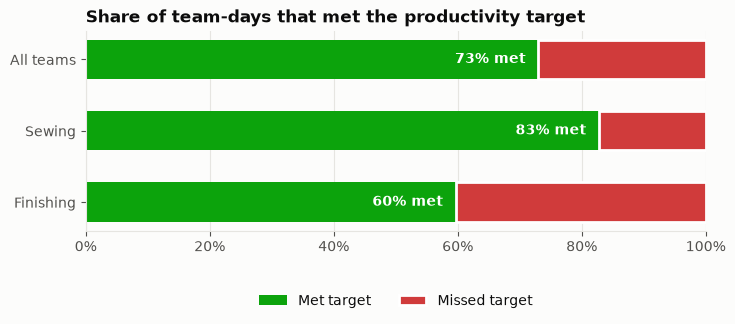

In [4]:
fig, ax = plt.subplots(figsize=(8, 2.6))
labels = ["All teams"] + [d.title() for d in DEPTS]
rates = [df["met"].mean()] + [df.loc[df["department"] == d, "met"].mean() for d in DEPTS]

ax.barh(labels, rates, color=STATUS_COLORS["met"], height=0.55, label="Met target")
ax.barh(labels, [1 - r for r in rates], left=rates, color=STATUS_COLORS["missed"],
        height=0.55, label="Missed target", edgecolor="white", linewidth=2)
for y, r in enumerate(rates):
    ax.text(r - 0.02, y, f"{r:.0%} met", va="center", ha="right", color="white", fontweight="bold")
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.45), ncol=2)
ax.set_title("Share of team-days that met the productivity target")
save_figure(fig, "eda_01_target_balance")
plt.show()

**Findings**
- **73%** of team-days meet the target and **27%** miss. The classes are imbalanced, so in modelling we use **stratified** splits and judge models by **F1**, not just accuracy. A model that always says "met" would already score 73% accuracy.
- **Finishing misses much more often** (60% met) than **sewing** (83% met).

## 2. How far above or below target?

`gap` = actual minus targeted productivity. Above 0 means the target was met.

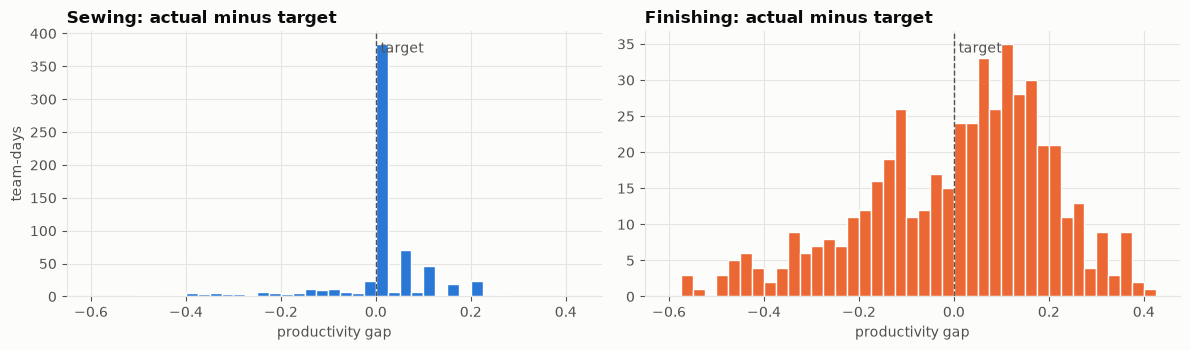

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=False)
bins = np.arange(-0.6, 0.45, 0.025)
for ax, dept in zip(axes, DEPTS):
    gap = df.loc[df["department"] == dept, "gap"]
    ax.hist(gap, bins=bins, color=DEPARTMENT_COLORS[dept], edgecolor="white", linewidth=1)
    ax.axvline(0, color=TEXT_SECONDARY, linestyle="--", linewidth=1)
    ax.text(0.01, ax.get_ylim()[1] * 0.92, "target", color=TEXT_SECONDARY)
    ax.set_title(f"{dept.title()}: actual minus target")
    ax.set_xlabel("productivity gap")
axes[0].set_ylabel("team-days")
plt.tight_layout()
save_figure(fig, "eda_02_gap_distribution")
plt.show()

In [6]:
near_target = df["gap"].between(0, 0.01)
near_target.groupby(df["department"], observed=True).mean().rename("share just at target (0 to +0.01)")

department
sewing       0.562952
finishing    0.021739
Name: share just at target (0 to +0.01), dtype: float64

**Findings**
- **Sewing has a tall spike right at 0**: 56% of sewing team-days land within +0.01 of the target. It looks like sewing productivity is often recorded as "target reached" rather than the exact value. When a sewing team misses, it usually misses by a lot.
- **Finishing is spread out** with no spike. It is noisier and harder to predict.
- **Impact on the model:** for sewing, "met vs missed" is mostly about avoiding big problems, not small differences. Expect finishing to be the harder half.

## 3. Teams

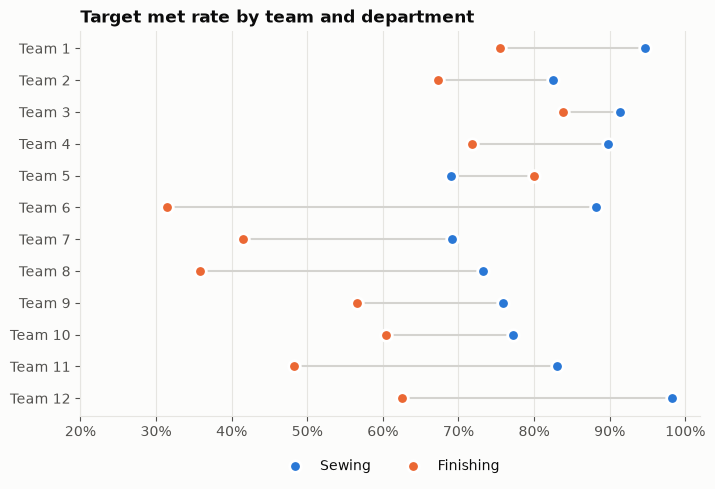

In [7]:
team_rates = (
    df.pivot_table(index="team", columns="department", values="met", aggfunc="mean", observed=True)
    [DEPTS]
)

fig, ax = plt.subplots(figsize=(8, 5))
for team in team_rates.index:
    ax.plot(team_rates.loc[team, DEPTS], [team, team], color="#d4d3cf", linewidth=1.5, zorder=1)
for dept in DEPTS:
    ax.scatter(team_rates[dept], team_rates.index, s=70, color=DEPARTMENT_COLORS[dept],
               edgecolor="white", linewidth=2, label=dept.title(), zorder=2)
ax.set_yticks(team_rates.index, [f"Team {t}" for t in team_rates.index])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0.2, 1.02)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
ax.set_title("Target met rate by team and department")
save_figure(fig, "eda_03_team_met_rate")
plt.show()

In [8]:
team_rates.style.format("{:.0%}").background_gradient(cmap="Blues", vmin=0.3, vmax=1)

department,sewing,finishing
team,,
1,95%,76%
2,82%,67%
3,91%,84%
4,90%,72%
5,69%,80%
6,88%,31%
7,69%,41%
8,73%,36%
9,76%,57%


**Findings**
- Big differences between teams. In **sewing**, teams 1, 3, 4 and 12 meet the target about 90% of the time or more, while teams 5 and 7 only reach about 70%.
- In **finishing**, teams **6, 7 and 8** are the weakest (31% to 41%). Teams 7 and 8 are also below average in sewing, so they may share a common problem (supervision, skill mix or product type).
- **Impact on the model:** `team` should be a feature, kept separate per department.

## 4. Performance over time

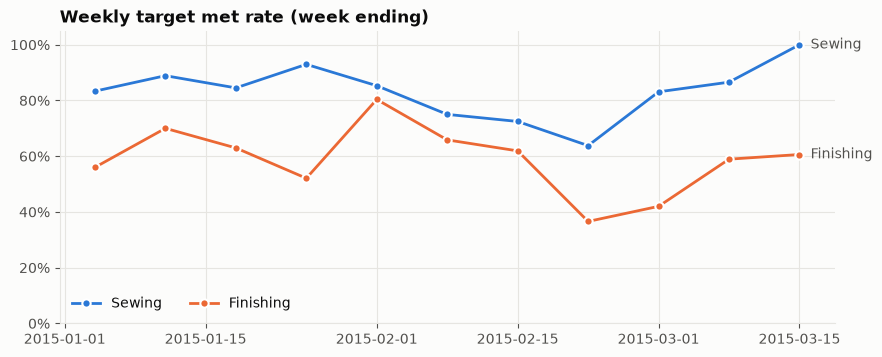

In [9]:
weekly = (
    df.groupby([pd.Grouper(key="date", freq="W"), "department"], observed=True)["met"]
    .mean()
    .unstack()[DEPTS]
)

fig, ax = plt.subplots(figsize=(10, 3.8))
for dept in DEPTS:
    ax.plot(weekly.index, weekly[dept], color=DEPARTMENT_COLORS[dept], marker="o",
            markersize=6, markeredgecolor="white", markeredgewidth=1.5, label=dept.title())
    ax.annotate(dept.title(), (weekly.index[-1], weekly[dept].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=TEXT_SECONDARY)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1.05)
ax.legend(loc="lower left", ncol=2)
ax.set_title("Weekly target met rate (week ending)")
save_figure(fig, "eda_04_weekly_met_rate")
plt.show()

In [10]:
by_day = df.groupby("day", observed=True)["met"].mean()
by_quarter = df.groupby("quarter", observed=True)["met"].mean()
pd.concat([by_day, by_quarter], keys=["day", "week of month"]).to_frame("met_rate").style.format("{:.0%}")

**Findings**
- Both departments **dip in the second half of February**. Finishing falls furthest (to about 37% in the week ending 22 Feb), and sewing drops to about 64%. Those are the same weeks with idle-time events and many sewing days with zero incentive (see section 5).
- Sewing is above finishing in every single week.
- Day of week and week of month make little difference (67% to 77%). Thursday and Sunday are slightly lower, and so is Quarter3 (days 15 to 21).
- **Impact on the model:** the data only covers 10 weeks, so we should **not** use the date itself as a feature. `day` and `quarter` can stay, but expect them to be weak.

## 5. What helps or hurts?

### 5a. Incentive (sewing)

Finishing almost never gets incentive (10 of 506 rows, all on one day), so we look at sewing only.

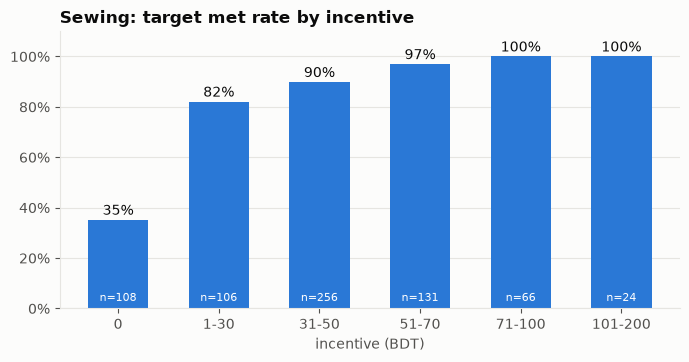

,rows,met_rate,avg_productivity
incentive,,,
0,108,35%,0.53
1-30,106,82%,0.59
31-50,256,90%,0.75
51-70,131,97%,0.80
71-100,66,100%,0.88
101-200,24,100%,1.00


In [11]:
sewing = df[df["department"] == "sewing"]
bands = pd.cut(sewing["incentive"], [-1, 0, 30, 50, 70, 100, 200],
               labels=["0", "1-30", "31-50", "51-70", "71-100", "101-200"])
incentive_table = sewing.groupby(bands, observed=True).agg(
    rows=("met", "size"), met_rate=("met", "mean"), avg_productivity=("actual_productivity", "mean")
)

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(incentive_table.index.astype(str), incentive_table["met_rate"],
              color=DEPARTMENT_COLORS["sewing"], width=0.6)
for bar, (rate, n) in zip(bars, incentive_table[["met_rate", "rows"]].values):
    ax.text(bar.get_x() + bar.get_width() / 2, rate + 0.02, f"{rate:.0%}", ha="center")
    ax.text(bar.get_x() + bar.get_width() / 2, 0.03, f"n={n:.0f}", ha="center", color="white", fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1.1)
ax.grid(axis="x", visible=False)
ax.set_xlabel("incentive (BDT)")
ax.set_title("Sewing: target met rate by incentive")
save_figure(fig, "eda_05_incentive_sewing")
plt.show()
incentive_table.style.format({"rows": "{:.0f}", "met_rate": "{:.0%}", "avg_productivity": "{:.2f}"})

In [12]:
# Is incentive a cause of good days, or a reward for them?
sewing_sorted = sewing.sort_values(["team", "date"]).copy()
sewing_sorted["met_previous_day"] = sewing_sorted.groupby("team")["met"].shift()
print("Spearman correlation, incentive vs actual productivity:",
      round(sewing[["incentive", "actual_productivity"]].corr(method="spearman").iloc[0, 1], 2))
sewing_sorted.groupby("met_previous_day")["incentive"].mean().rename("avg incentive today")

Spearman correlation, incentive vs actual productivity: 0.85


met_previous_day
False    14.218487
True     50.887500
Name: avg incentive today, dtype: float64

**Findings**
- Incentive is the **strongest signal in the data**: with 0 incentive only **35%** of sewing team-days meet the target, while with more than 70 BDT it is **100%**.
- ⚠️ **But be careful.** Incentive moves almost in lockstep with productivity (Spearman 0.85), and teams that met the target *yesterday* get much more incentive today (51 vs 14 BDT). Garment factories often pay incentive **based on output**, so incentive may be partly a **result** of high productivity, not only a cause.
- **Impact on the model:** if incentive is set after the day's output is known, using it would **leak the answer**, and the model would look great in testing but fail in real use. In notebook 04 we will train **with and without incentive** and compare. For the live dashboard, only values known *during* the day can be used.

### 5b. Disruptions: idle time and style changes

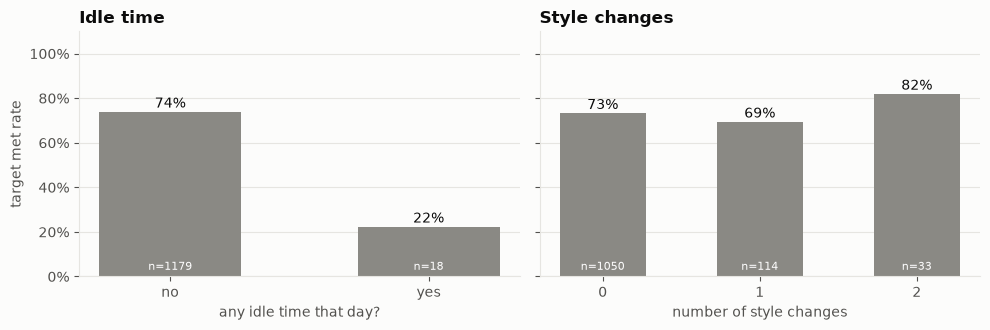

In [13]:
disruptions = {
    "Idle time": df.groupby(np.where(df["idle_time"] > 0, "yes", "no"))["met"].agg(["mean", "size"]),
    "Style changes": df.groupby(df["no_of_style_change"].astype(str))["met"].agg(["mean", "size"]),
}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (title, table) in zip(axes, disruptions.items()):
    bars = ax.bar(table.index, table["mean"], color=NEUTRAL, width=0.55)
    for bar, (rate, n) in zip(bars, table.values):
        ax.text(bar.get_x() + bar.get_width() / 2, rate + 0.02, f"{rate:.0%}", ha="center")
        ax.text(bar.get_x() + bar.get_width() / 2, 0.03, f"n={n:.0f}", ha="center", color="white", fontsize=8)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
axes[0].set_xlabel("any idle time that day?")
axes[1].set_xlabel("number of style changes")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_ylim(0, 1.1)
axes[0].set_ylabel("target met rate")
plt.tight_layout()
save_figure(fig, "eda_06_disruptions")
plt.show()

**Findings**
- **Idle time is rare but serious**: only 18 team-days had any, and just **22%** of those met the target, compared with 74% normally.
- **Style changes** (switching to a new garment style) lower average productivity (0.75 with none, 0.62 with one). The effect on met rate is mixed (two changes looks fine, but that is only 33 rows).
- **Impact on the model:** both are real-time signals a supervisor knows during the shift, so they are good inputs for the live dashboard. They are rare, so the model may underweight them.

## 6. What moves together with productivity?

Correlation with `actual_productivity`, calculated **separately per department**, since finishing has no WIP, idle time or style changes.

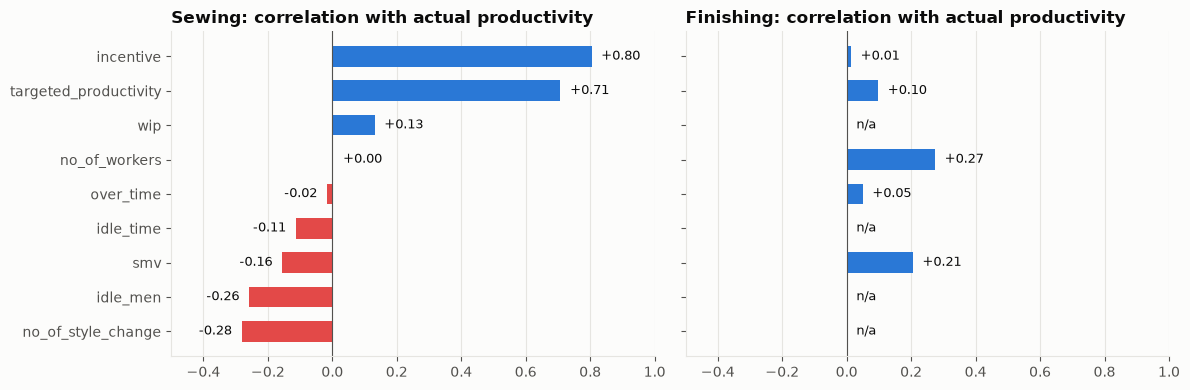

,sewing,finishing
targeted_productivity,0.71,0.10
smv,-0.16,0.21
wip,0.13,NaN
over_time,-0.02,0.05
incentive,0.80,0.01
idle_time,-0.11,NaN
idle_men,-0.26,NaN
no_of_style_change,-0.28,NaN
no_of_workers,0.00,0.27


In [14]:
numeric = ["targeted_productivity", "smv", "wip", "over_time", "incentive",
           "idle_time", "idle_men", "no_of_style_change", "no_of_workers"]

corr = pd.DataFrame({
    dept: df[df["department"] == dept][numeric].corrwith(df["actual_productivity"])
    for dept in DEPTS
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
order = corr["sewing"].sort_values().index
for ax, dept in zip(axes, DEPTS):
    values = corr.loc[order, dept]
    colors = [POSITIVE if v >= 0 else NEGATIVE for v in values.fillna(0)]
    ax.barh(order, values.fillna(0), color=colors, height=0.6)
    for y, v in enumerate(values):
        label = "n/a" if pd.isna(v) else f"{v:+.2f}"
        ax.text((0 if pd.isna(v) else v) + (0.03 if (pd.isna(v) or v >= 0) else -0.03), y, label,
                va="center", ha="left" if (pd.isna(v) or v >= 0) else "right", fontsize=9)
    ax.axvline(0, color=TEXT_SECONDARY, linewidth=0.8)
    ax.set_xlim(-0.5, 1)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{dept.title()}: correlation with actual productivity")
plt.tight_layout()
save_figure(fig, "eda_07_correlations")
plt.show()
corr.round(2)

**Findings**
- **Sewing:** incentive (+0.80) and target level (+0.71) go with high productivity. Teams given higher targets tend to be the stronger teams, so the target reflects expected ability. Idle workers and style changes go with lower productivity.
- **Finishing:** nothing is strongly correlated. Team size (+0.27) and SMV (+0.21) are the strongest, which confirms finishing is harder to explain from these columns.
- `n/a` means the value never changes in finishing (always 0), so there is no correlation to compute.
- Overtime has almost no relationship with productivity in either department.

## Summary: what this means for modelling

| Finding | What to do in notebooks 03 and 04 |
|---|---|
| 73% met, 27% missed | Stratified splits; judge models by F1, precision and recall |
| Sewing and finishing behave very differently | Keep `department` as a feature; report results per department; consider separate models |
| 56% of sewing rows sit exactly at target | Sewing misses are mostly big; finishing will be the harder half |
| Strong team differences (teams 6, 7, 8 weak in finishing) | Keep `team` as a feature |
| Incentive is the strongest signal, but may be paid **because** of output | ⚠️ Train with and without incentive and compare; avoid leaking the answer |
| Idle time and style changes hurt, but are rare | Keep them; they are useful live signals for the dashboard |
| Overtime, day and week of month are weak | Keep, but don't expect much; per-worker overtime may help a little |
| Only 10 weeks of data | Don't use the raw date as a feature |

**Next:** notebook 03 creates the real `met_target` column and builds the model features.